# Performance study of the submitted linear model ("pfss-dhcs")

Diagnostic only: nothing is selected or changed from it.

- **Model:** the submitted linear model with `pfss_d_hcs_lead_72h` (staging tag `upload_candidate/pfss-dhcs`).
- **Forecasts:**
  - out-of-fold on the six yearly folds (refitted on the years before each fold; 8,768 runs);
  - the shipped asset on the eval year (1,448 runs), a descriptive check only.
- **Truth:** SWPC's hourly ACE file. **Residual = observed − forecast** (negative: over-forecast).
- **Regimes** (training.solar_wind_events, fixed before looking at errors):
  - **per run,** from the 72 target hours: CME (including possible CME), stream arrival, fast stream, intermediate, slow wind;
  - **per hour:** CME, else slow < 450, intermediate 450–550, fast ≥ 550 km/s.

Study: `python -m training.model_diagnostics`; write-up `docs/model_diagnostics.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from models.linear_model import LinearModel
from training import model_diagnostics as dg

pd.set_option("display.width", 160)
results = dg.load_results()
P = dg.pooled(results)
E = results[dg.EVAL]
for r in (P, E):
    r["res"] = r["obs"] - r["f_lin"]
    r["hreg"] = dg.hour_regimes(r["obs"], dg.cached_cme_hours(r["t0s"]))
regimes = pd.read_csv(dg.EXPERIMENTS / "model_diagnostics_regimes.csv")
residuals = pd.read_csv(dg.EXPERIMENTS / "model_diagnostics_residuals.csv")
importance = pd.read_csv(dg.EXPERIMENTS / "model_diagnostics_importance.csv")
folds = [p for p in results if p != dg.EVAL]
g = regimes[(regimes.regime == "all") & regimes.period.isin(folds)]["linear / persistence"]
print(f"geometric mean over folds: {np.exp(np.log(g).mean()):.4f} (shipped: 0.7794)")

geometric mean over folds: 0.7794 (shipped: 0.7794)


# (i) Performance by regime

## Per run regime (official S_final)

In [2]:
cols = ["period", "regime", "runs", "share", "linear / persistence", "baseline / persistence",
        "rmse linear", "rmse persistence", "residual linear", "beats persistence (run rmse)"]
tab = regimes[regimes.period.isin(["folds pooled", dg.EVAL])][cols]
tab.round(3)

,period,regime,runs,share,linear / persistence,baseline / persistence,rmse linear,rmse persistence,residual linear,beats persistence (run rmse)
36,eval year,all,1448,1.000,0.750,0.837,82.766,105.060,-29.040,0.658
37,eval year,CME,376,0.260,0.739,0.822,98.325,130.429,-25.863,0.707
38,eval year,stream arrival,304,0.210,0.692,0.716,83.535,120.555,7.125,0.806
39,eval year,fast stream,105,0.073,0.780,0.804,83.856,106.251,-30.258,0.743
40,eval year,intermediate,477,0.329,0.761,0.792,71.027,85.246,-44.935,0.633
41,eval year,slow wind,186,0.128,1.223,1.619,69.604,51.748,-52.221,0.333
42,folds pooled,all,8768,1.000,0.787,0.879,69.852,79.138,-24.623,0.548
43,folds pooled,CME,1903,0.217,0.809,0.894,76.367,90.918,-18.538,0.568
44,folds pooled,stream arrival,1476,0.168,0.645,0.733,77.284,110.798,5.755,0.776
45,folds pooled,fast stream,266,0.030,0.795,0.958,86.732,104.598,-7.514,0.628


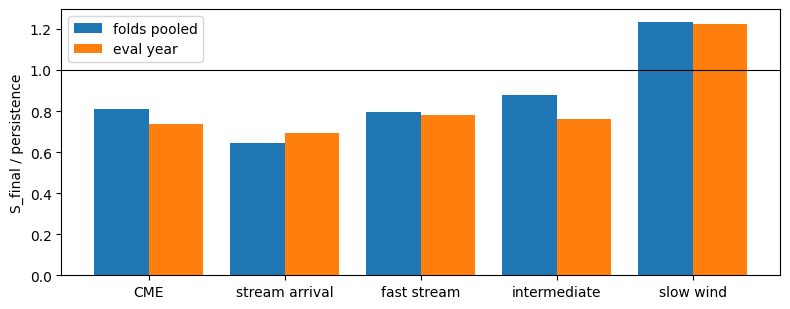

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.2))
order = list(dg.RUN_REGIMES)
for period, off in (("folds pooled", -0.2), (dg.EVAL, 0.2)):
    t = tab[tab.period == period].set_index("regime").reindex(order)
    ax.bar(np.arange(len(order)) + off, t["linear / persistence"], 0.4, label=period)
ax.axhline(1, color="k", lw=.8)
ax.set_xticks(range(len(order)), order)
ax.set_ylabel("S_final / persistence")
ax.legend()
plt.tight_layout()

Caveat: the run regimes are defined from what was observed in the 72 target hours. Runs
labelled "slow wind" are by construction the ones where nothing arrived, which favours
persistence; "stream arrival" runs are the ones where persistence must fail. The regime
table describes where the model's skill comes from, not how it would do if the regime were
known in advance.

## Per fold

In [4]:
pf = regimes[regimes.period.isin(folds)].pivot(index="regime", columns="period",
                                                values="linear / persistence")
pf.reindex(["all", *order]).round(3)

period,2019,2020,2021,2022,2023,2024
regime,,,,,,
all,0.720,0.691,0.809,0.852,0.833,0.785
CME,0.591,0.723,0.933,0.824,0.803,0.788
stream arrival,0.672,0.580,0.692,0.745,0.667,0.626
fast stream,0.775,0.886,0.881,0.800,0.709,0.775
intermediate,0.691,0.787,0.771,0.919,0.802,1.104
slow wind,0.942,1.079,1.203,1.745,1.228,2.116


## Per hourly regime, by lead

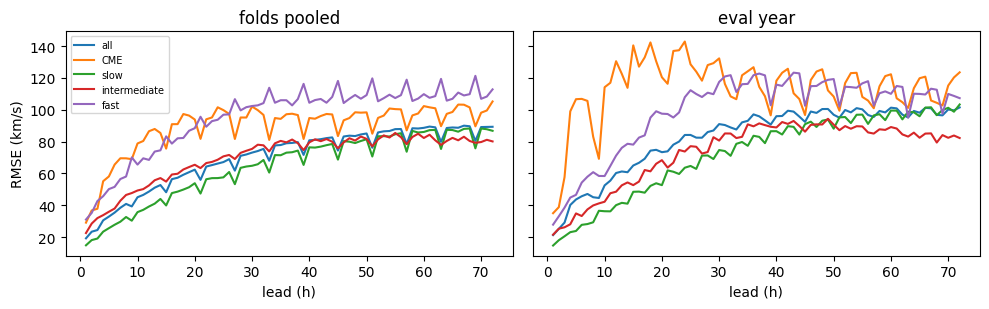

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, period in zip(axes, ("folds pooled", dg.EVAL), strict=True):
    for reg in ("all", *dg.HOUR_REGIMES):
        c = residuals[(residuals.period == period) & (residuals.regime == reg)
                      & (residuals.lead > 0)]
        ax.plot(c.lead, c.rmse, label=reg)
    ax.set_title(period)
    ax.set_xlabel("lead (h)")
axes[0].set_ylabel("RMSE (km/s)")
axes[0].legend(fontsize=7)
plt.tight_layout()

## Error budget: share of squared error against share of hours

In [6]:
residuals[residuals.lead == 0][["period", "regime", "n", "residual", "rmse", "mae",
                                "share of squared error", "share of hours"]].round(3)

,period,regime,n,residual,rmse,mae,share of squared error,share of hours
72,folds pooled,all,444647,-25.224,73.038,54.520,1.000,1.000
145,folds pooled,CME,27024,11.746,91.856,67.925,0.096,0.061
218,folds pooled,slow,306387,-41.409,68.138,50.928,0.600,0.689
291,folds pooled,intermediate,76508,-3.403,72.115,54.693,0.168,0.172
364,folds pooled,fast,34728,40.722,96.528,75.399,0.136,0.078
437,eval year,all,72403,-28.709,85.862,63.918,1.000,1.000
510,eval year,CME,5712,10.367,116.577,80.886,0.145,0.079
583,eval year,slow,36988,-51.376,76.794,58.251,0.409,0.511
656,eval year,intermediate,16323,-35.561,76.701,58.602,0.180,0.225
729,eval year,fast,13380,25.630,103.016,78.826,0.266,0.185


# (ii) Residuals

## Bias by lead

,residual,rmse,mae
lead,,,
1,-1.6,19.2,12.6
6,-6.6,35.4,24.9
24,-22.4,66.2,50.6
48,-32.3,83.5,65.6
72,-34.2,89.3,70.2


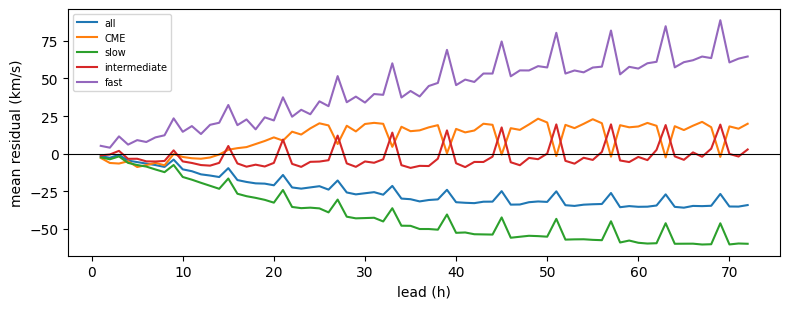

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for reg in ("all", *dg.HOUR_REGIMES):
    c = residuals[(residuals.period == "folds pooled") & (residuals.regime == reg)
                  & (residuals.lead > 0)]
    ax.plot(c.lead, c.residual, label=reg)
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("lead (h)")
ax.set_ylabel("mean residual (km/s)")
ax.legend(fontsize=7)
plt.tight_layout()
c = residuals[(residuals.period == "folds pooled") & (residuals.regime == "all")]
c.set_index("lead").loc[[1, 6, 24, 48, 72], ["residual", "rmse", "mae"]].round(1)

## Distribution

,mean,sd,skew,excess kurtosis,q1,q5,q25,q50,q75,q95,q99
1 h,-1.63,19.15,0.97,14.89,-47.58,-27.73,-10.51,-2.18,6.09,26.25,57.14
24 h,-22.45,62.28,0.73,3.01,-163.71,-116.13,-58.69,-26.07,7.99,82.32,168.81
48 h,-32.28,76.98,0.42,1.76,-212.39,-151.87,-78.28,-36.31,9.69,101.61,177.90
72 h,-34.18,82.50,0.38,1.41,-229.12,-166.22,-84.94,-37.09,11.58,104.83,188.27


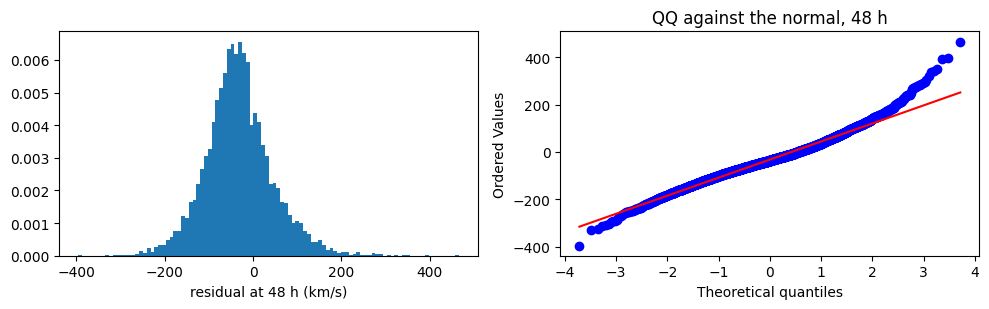

In [8]:
rows = {}
for lead in (1, 24, 48, 72):
    e = P["res"][:, lead - 1]
    e = e[np.isfinite(e)]
    rows[f"{lead} h"] = {"mean": e.mean(), "sd": e.std(), "skew": stats.skew(e),
                         "excess kurtosis": stats.kurtosis(e),
                         **{f"q{q}": np.percentile(e, q) for q in (1, 5, 25, 50, 75, 95, 99)}}
dist = pd.DataFrame(rows).T
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
e = P["res"][:, 47]
e = e[np.isfinite(e)]
axes[0].hist(e, bins=100, density=True)
axes[0].set_xlabel("residual at 48 h (km/s)")
stats.probplot(e, dist="norm", plot=axes[1])
axes[1].set_title("QQ against the normal, 48 h")
plt.tight_layout()
dist.round(2)

## Conditional bias

,forecast,observed,last speed
b,,,
"(250, 300]",24.1,-65.8,-6.4
"(300, 350]",2.9,-52.3,-11.7
"(350, 400]",-7.6,-42.2,-20.5
"(400, 450]",-20.6,-24.5,-24.9
"(450, 500]",-35.0,-6.1,-32.3
"(500, 550]",-43.7,9.6,-41.2
"(550, 600]",-61.6,26.3,-45.7
"(600, 650]",-75.5,50.1,-53.5
"(650, 700]",-90.2,74.8,-57.4


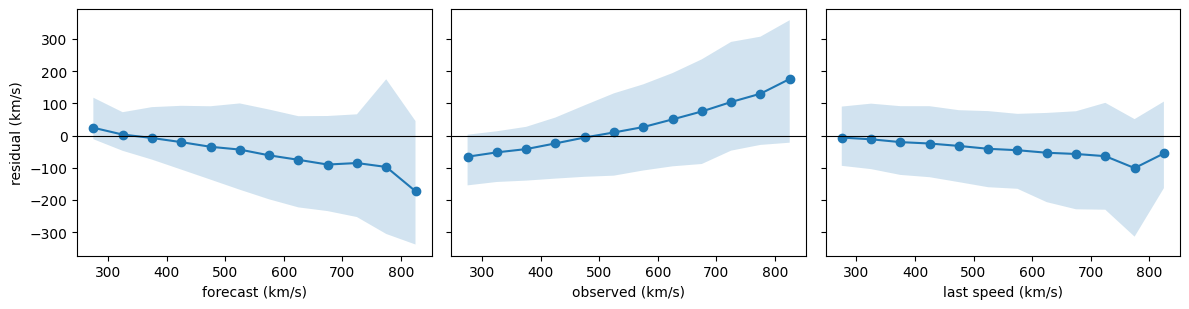

In [9]:
def binned(x, y, bins):
    x, y = x.ravel(), y.ravel()
    ok = np.isfinite(x) & np.isfinite(y)
    b = pd.cut(x[ok], bins)
    return pd.DataFrame({"y": y[ok], "b": b}).groupby("b", observed=True)["y"].describe(
        percentiles=[.05, .5, .95])[["count", "mean", "5%", "50%", "95%"]]

bins = np.arange(250, 851, 50)
last = np.repeat(P["last"][:, None], 72, 1)
cond = {"forecast": binned(P["f_lin"], P["res"], bins),
        "observed": binned(P["obs"], P["res"], bins),
        "last speed": binned(last, P["res"], bins)}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, (name, t) in zip(axes, cond.items(), strict=True):
    mid = [i.mid for i in t.index]
    ax.plot(mid, t["mean"], marker="o")
    ax.fill_between(mid, t["5%"], t["95%"], alpha=.2)
    ax.axhline(0, color="k", lw=.8)
    ax.set_xlabel(f"{name} (km/s)")
axes[0].set_ylabel("residual (km/s)")
plt.tight_layout()
pd.concat({k: v["mean"] for k, v in cond.items()}, axis=1).round(1)

Against the forecast, the residual measures calibration (what a post-step could fix);
against the observed speed it mostly shows regression to the mean, which every forecast
that cannot see the future has.

## Timing against amplitude (stream arrivals and CMEs)

,runs,median shift (h),mean |shift| (h),share |shift| <= 3 h,share at +-24 h bound
stream arrival,1421.0,-1.0,11.36,0.22,0.10
CME,1827.0,-4.0,14.31,0.14,0.21
slow wind,2517.0,6.0,17.53,0.08,0.36


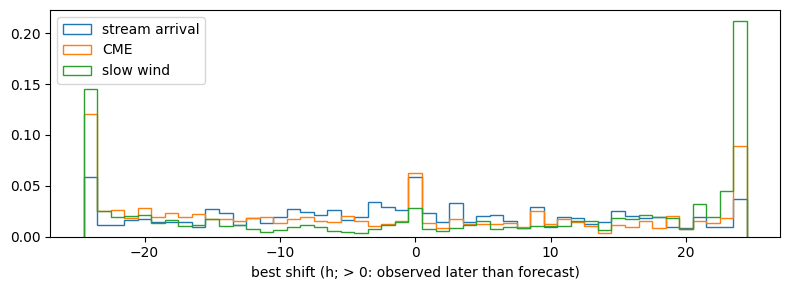

In [10]:
shift = dg.best_shift(P["f_lin"], P["obs"])
tim = {}
fig, ax = plt.subplots(figsize=(8, 3))
for reg in ("stream arrival", "CME", "slow wind"):
    s = shift[(P["regime"] == reg) & np.isfinite(shift)]
    tim[reg] = {"runs": len(s), "median shift (h)": np.median(s),
                "mean |shift| (h)": np.abs(s).mean(),
                "share |shift| <= 3 h": (np.abs(s) <= 3).mean(),
                "share at +-24 h bound": (np.abs(s) == 24).mean()}
    ax.hist(s, bins=np.arange(-24.5, 25), histtype="step", density=True, label=reg)
ax.set_xlabel("best shift (h; > 0: observed later than forecast)")
ax.legend()
plt.tight_layout()
pd.DataFrame(tim).T.round(2)

In [11]:
# how much of the error the best shift removes, by regime
def rmse_shifted(f, y, s):
    out = np.full(len(f), np.nan)
    for i in np.flatnonzero(np.isfinite(s)):
        k = int(s[i])
        a, b = (y[i, k:], f[i, :72 - k]) if k >= 0 else (y[i, :72 + k], f[i, -k:])
        out[i] = np.sqrt(np.nanmean((a - b) ** 2))
    return out

r0 = np.sqrt(np.nanmean(P["res"] ** 2, axis=1))
r1 = rmse_shifted(P["f_lin"], P["obs"], shift)
pd.DataFrame({reg: {"run rmse": np.nanmean(r0[m]), "after best shift": np.nanmean(r1[m])}
              for reg in dg.RUN_REGIMES for m in [P["regime"] == reg]}).T.round(1)

,run rmse,after best shift
CME,70.2,56.6
stream arrival,72.9,59.6
fast stream,78.1,63.3
intermediate,63.4,51.0
slow wind,54.8,43.2


## Persistence of errors

In [12]:
res = P["res"]
def lag_corr(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[ok], b[ok])[0, 1]

within = {lag: lag_corr(res[:, 0], res[:, lag]) for lag in (1, 6, 12, 24, 48, 71)}
run_mean = pd.Series(np.nanmean(res, axis=1), index=P["t0s"])
across = {f"{6 * k} h": run_mean.autocorr(k) for k in (1, 2, 4, 8, 12, 108)}
print("residual at lead 1 against lead 1 + lag:",
      {f"{k} h": round(float(v), 3) for k, v in within.items()})
print("run-mean residual against the run k cycles later:",
      {k: round(float(v), 3) for k, v in across.items()})

residual at lead 1 against lead 1 + lag: {'1 h': 0.832, '6 h': 0.523, '12 h': 0.377, '24 h': 0.217, '48 h': 0.106, '71 h': 0.057}
run-mean residual against the run k cycles later: {'6 h': 0.898, '12 h': 0.781, '24 h': 0.539, '48 h': 0.163, '72 h': 0.037, '648 h': 0.114}


## Drift: by fold, year and month

,residual,rmse
fold,,
2019,-10.0,43.3
2020,-19.6,57.2
2021,-20.2,64.9
2022,-27.1,70.0
2023,-22.6,63.9
2024,-50.6,86.6


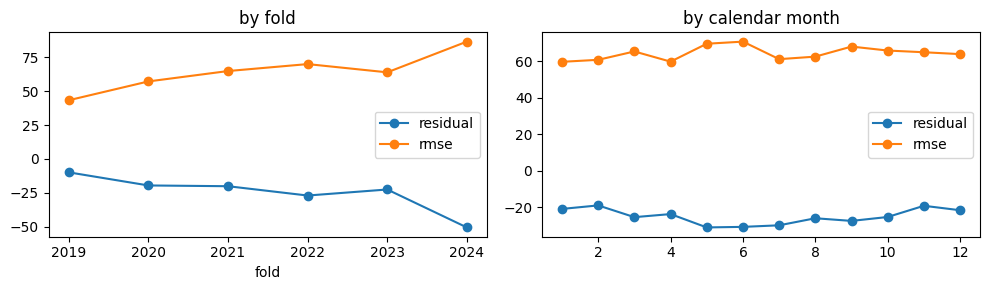

In [13]:
rm = pd.DataFrame({"residual": np.nanmean(P["res"], axis=1),
                   "rmse": np.sqrt(np.nanmean(P["res"] ** 2, axis=1)),
                   "fold": P["period"]}, index=P["t0s"])
by_fold = rm.groupby("fold")[["residual", "rmse"]].mean()
by_month = rm.groupby(rm.index.month)[["residual", "rmse"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
by_fold.plot(ax=axes[0], marker="o")
by_month.plot(ax=axes[1], marker="o")
axes[0].set_title("by fold")
axes[1].set_title("by calendar month")
plt.tight_layout()
by_fold.round(1)

## Input quality: runs on the submodel or with the PFSS value imputed

In [14]:
q = {}
for name, r in (("folds", P), (dg.EVAL, E)):
    for label, m in (("complete", ~r["submodel"] & ~r["pfss_imputed"]),
                     ("submodel (no coronal-hole strip)", r["submodel"]),
                     ("PFSS imputed", r["pfss_imputed"])):
        e = r["res"][m]
        q[(name, label)] = {"runs": int(m.sum()), "share": m.mean(),
                            "residual": np.nanmean(e), "rmse": np.sqrt(np.nanmean(e ** 2))}
pd.DataFrame(q).T.round(3)

runs  share  residual     rmse
folds     complete                          7769.0  0.886   -25.594   72.864
          submodel (no coronal-hole strip)   331.0  0.038   -44.652   97.350
          PFSS imputed                       668.0  0.076   -10.936   59.423
eval year complete                          1092.0  0.754   -27.865   81.063
          submodel (no coronal-hole strip)   292.0  0.202   -30.142  102.420
          PFSS imputed                        66.0  0.046   -41.521   86.769

## Worst runs (folds, by run RMSE)

In [15]:
worst = pd.DataFrame({"run rmse": r0, "residual": np.nanmean(P["res"], axis=1),
                      "regime": P["regime"], "last": P["last"],
                      "max observed": np.nanmax(P["obs"], axis=1),
                      "max forecast": np.nanmax(P["f_lin"], axis=1)},
                     index=P["t0s"]).sort_values("run rmse", ascending=False)
print(worst.head(200).regime.value_counts().to_dict())
worst.head(20).round(0)

{'intermediate': 80, 'CME': 47, 'stream arrival': 34, 'slow wind': 30, 'fast stream': 9}


,run rmse,residual,regime,last,max observed,max forecast
2024-05-10 12:00:00+00:00,341.0,331.0,CME,404.0,963.0,493.0
2024-05-10 06:00:00+00:00,332.0,306.0,CME,417.0,963.0,495.0
2024-05-10 00:00:00+00:00,310.0,271.0,CME,404.0,963.0,503.0
2024-05-09 18:00:00+00:00,289.0,237.0,CME,416.0,963.0,506.0
2025-03-27 12:00:00+00:00,275.0,-259.0,fast stream,794.0,807.0,896.0
2025-06-01 12:00:00+00:00,272.0,-263.0,CME,1052.0,1002.0,1087.0
2025-04-21 18:00:00+00:00,267.0,-235.0,fast stream,659.0,658.0,885.0
2025-06-05 00:00:00+00:00,263.0,-244.0,intermediate,727.0,708.0,768.0
2025-03-28 00:00:00+00:00,262.0,-250.0,intermediate,765.0,716.0,833.0
2024-05-09 12:00:00+00:00,261.0,197.0,CME,426.0,963.0,510.0


# (iii) Feature importance

## Refit without the input, and shuffle the input (all runs)

change (folds)  folds worse  change eval year
method  input                                                               
drop    bt_mean_1h                       1.06            5               NaN
        ch_cm_lead_72h                   5.41            5               NaN
        xray_peak_max_72h                0.24            3               NaN
        density_mean_24h                 0.45            4               NaN
        pfss_d_hcs_lead_72h              1.69            5               NaN
        recurrence 13.5 d               -0.15            1               NaN
        recurrence 27 d                  2.06            4               NaN
        both recurrence terms            1.88            3               NaN
permute bt_mean_1h                       3.03            6              2.23
        ch_cm_lead_72h                   9.73            6              7.61
        xray_peak_max_72h                0.32            5              1.16
        density_mean_24h                 0.78            5              1.55
        pfss_d_hcs_lead_72h              4.19            6              6.12

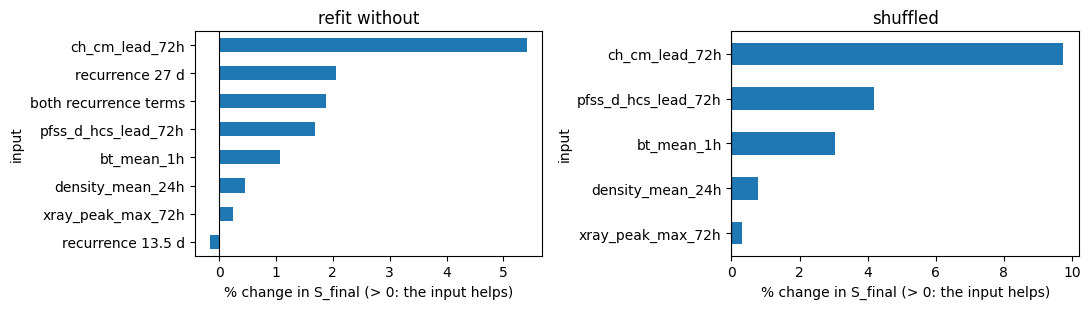

In [16]:
imp = importance[importance.regime == "all"].set_index(["method", "input"])
show = ["change (folds)", "folds worse", "change eval year"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, method in zip(axes, ("drop", "permute"), strict=True):
    s = 100 * imp.loc[method, "change (folds)"].sort_values()
    s.plot.barh(ax=ax)
    ax.axvline(0, color="k", lw=.8)
    ax.set_xlabel("% change in S_final (> 0: the input helps)")
    ax.set_title({"drop": "refit without", "permute": "shuffled"}[method])
plt.tight_layout()
(imp[show] * [100, 1, 100]).round(2)

## Importance by run regime (% change in S_final, folds)

In [17]:
for method in ("drop", "permute"):
    t = importance[importance.method == method].pivot(index="input", columns="regime",
                                                      values="change (folds)")
    print(method)
    display((100 * t[["all", *dg.RUN_REGIMES]]).round(2))

drop


regime,all,CME,stream arrival,fast stream,intermediate,slow wind
input,,,,,,
both recurrence terms,1.88,2.73,1.89,-3.26,0.60,2.13
bt_mean_1h,1.06,-1.24,3.20,5.66,1.03,0.05
ch_cm_lead_72h,5.41,8.76,1.13,6.20,5.60,7.48
density_mean_24h,0.45,0.41,0.05,0.38,1.37,0.53
pfss_d_hcs_lead_72h,1.69,1.70,2.26,2.71,-4.21,-4.92
recurrence 13.5 d,-0.15,-0.19,-0.14,-0.68,-0.04,-0.12
recurrence 27 d,2.06,2.98,2.04,-2.61,0.67,2.29
xray_peak_max_72h,0.24,1.53,2.39,2.71,-1.48,-5.06


permute


regime,all,CME,stream arrival,fast stream,intermediate,slow wind
input,,,,,,
bt_mean_1h,3.03,0.56,4.81,7.99,3.39,3.54
ch_cm_lead_72h,9.73,12.04,9.13,15.74,2.65,6.04
density_mean_24h,0.78,0.07,1.33,0.91,1.47,-0.57
pfss_d_hcs_lead_72h,4.19,4.38,3.73,5.50,-0.41,1.84
xray_peak_max_72h,0.32,0.94,-0.35,0.49,0.54,0.13


## Coefficients of the shipped asset, by lead

,last speed,recurrence 27 d,recurrence 13.5 d,bt_mean_1h,ch_cm_lead_72h,xray_peak_max_72h,density_mean_24h,pfss_d_hcs_lead_72h
1,-0.01,0.01,-0.00,2.92,1.70,-0.74,1.20,0.52
24,-0.31,0.10,-0.01,18.97,21.34,10.05,10.48,12.57
48,-0.55,0.20,-0.02,5.67,34.83,21.49,13.45,21.10
72,-0.67,0.25,-0.01,2.19,36.23,24.11,13.72,23.90


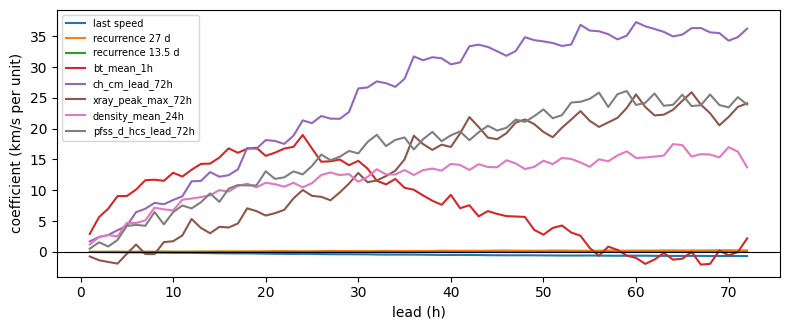

In [18]:
m = LinearModel.load()
names = dg.column_names(m.config)
coef = pd.DataFrame(m.coef[:, 1:], columns=names, index=np.arange(1, 73))
ax = coef.plot(figsize=(8, 3.4))
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("lead (h)")
ax.set_ylabel("coefficient (km/s per unit)")
ax.legend(fontsize=7)
plt.tight_layout()
coef.loc[[1, 24, 48, 72]].round(2)

The speed terms are in km/s (centred), the regressors per standard deviation. The model is
relative to persistence, so the last-speed coefficient is the change from persistence (−1 =
ignore the last speed).

## Mean absolute contribution (km/s), folds, runs on the full model

,all,CME,stream arrival,fast stream,intermediate,slow wind
last speed,32.200001,31.700001,25.799999,82.199997,35.200001,29.0
recurrence 27 d,12.000000,11.700000,14.000000,16.900000,10.500000,12.0
recurrence 13.5 d,1.000000,1.000000,1.200000,1.100000,1.000000,1.0
bt_mean_1h,8.300000,10.100000,9.300000,10.100000,7.300000,7.2
ch_cm_lead_72h,20.700001,20.900000,22.500000,29.000000,21.600000,18.0
xray_peak_max_72h,10.000000,11.100000,10.000000,10.200000,10.200000,8.9
density_mean_24h,5.000000,5.600000,5.100000,6.200000,5.300000,4.2
pfss_d_hcs_lead_72h,15.000000,15.900000,16.900000,29.600000,15.600000,11.4


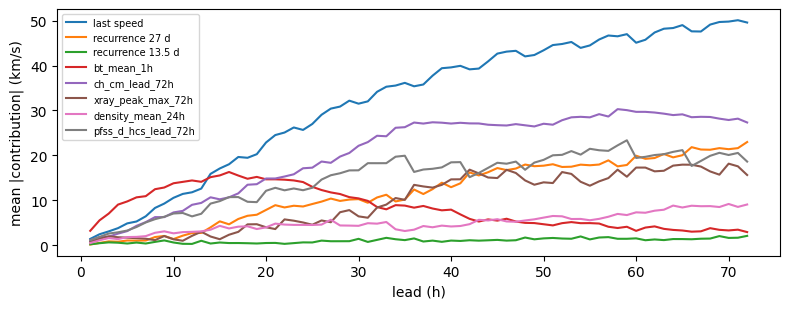

In [19]:
full = ~P["submodel"]
c = np.abs(P["contrib"][full])
by_lead = pd.DataFrame(c.mean(axis=0), columns=P["columns"], index=np.arange(1, 73))
ax = by_lead.plot(figsize=(8, 3.2))
ax.set_xlabel("lead (h)")
ax.set_ylabel("mean |contribution| (km/s)")
ax.legend(fontsize=7)
plt.tight_layout()
reg = P["regime"][full]
pd.DataFrame({"all": c.mean(axis=(0, 1)),
              **{r: c[reg == r].mean(axis=(0, 1)) for r in dg.RUN_REGIMES}},
             index=P["columns"]).round(1)